# Control points for the kiln ring analysis

For every charcoal kiln site, this notebook places matched control points: places in the same forest nearby, but not on a kiln. Running the ring analysis on them shows which patterns come from the sampling method itself and which come from the kilns.

**Rules for a control point**

1. It lies in forest (swissTLM3D) inside the Swiss National Park.
2. It is at least 48 m from every kiln, so its rings can't overlap any kiln's rings.
3. It is 50–100 m from its own kiln and at least 48 m from every other control.
4. At least 90% of its ray samples lie in forest inside the park (the same rule is applied to the kilns).
5. Its terrain (mean elevation, slope, aspect within 24 m, from `dtm.tif`) is similar to its kiln's.
6. If the height raster of the analysis is present: at least 90% of its ray samples have data.

Canopy heights are never used to choose points, only whether data exists.

**Inputs** (same folder as this notebook): `snp_boundaries.gpkg`, `swisstlm3d_forest.gpkg`, `kohlmeiler_2056.gpkg`, `dtm.tif`

**Outputs:** `controls_2056.gpkg`, `control_area_2056.gpkg`, `kiln_checks_2056.csv`

## Step 0: Settings
All parameters in one place. The ring geometry must match the one used in `kiln_ring_analysis`.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.font_manager import FontProperties
import rasterio
from rasterio.windows import from_bounds
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds as grid_transform
from shapely import contains_xy, prepare
from shapely.geometry import Point, LineString, box
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from adjustText import adjust_text



# --- input files -----------------------------------------------------------
SNP_FILE = "snp_boundaries.gpkg"
FOREST_FILE = "swisstlm3d_forest.gpkg"
KILN_FILE = "kohlmeiler_2056.gpkg"
DTM_FILE = "dtm.tif"
HEIGHT_RASTER = "merged_dem.tif"   # raster of the ring analysis; None = skip the coverage check
ID_COLUMN = "ID_PAROLINI"
CRS = "EPSG:2056"

# --- ring geometry of the analysis -------------------------------------------
RADIUS = 18          # outer ring radius (m)
N_RAYS = 8
STEP = 1             # sample spacing along the rays (m)

# --- placement rules -----------------------------------------------------------
N_PER_KILN = 3
SEARCH_MIN, SEARCH_MAX = 50, 100   # distance from its own kiln (m)
MIN_DIST_KILN = 2 * RADIUS         # to ANY kiln
MIN_DIST_CTRL = 2 * RADIUS         # between controls
MIN_FOREST = 0.9                   # share of ray samples in forest inside the park
MIN_VALID = 0.95                    # share of ray samples with data in HEIGHT_RASTER
N_CANDIDATES = 3000                # random candidates drawn per kiln
SEED = 0                           # same points every run

# --- terrain matching (control vs. its kiln) -----------------------------------
MAX_ELEV_DIFF = 30     # m
MAX_SLOPE_DIFF = 10    # degrees
MAX_ASPECT_DIFF = 45   # degrees; only checked where the kiln's slope is > FLAT_SLOPE
FLAT_SLOPE = 5         # degrees; below this, aspect is meaningless

# --- outputs ---------------------------------------------------------------------
OUT_AREA = "control_area_2056.gpkg"
OUT_POINTS = "controls_2056.gpkg"
OUT_KILN_CHECK = "kiln_checks_2056.csv"
FIG_DIR = Path("figures")         # relative to the notebook
FIG_DIR.mkdir(exist_ok=True)

# --- maps ---------------------------------------------------------------------
COLSCHEME = {
    "ember":  ["#FDBE85", "#F68C3A", "#D9541A"],
    "forest": ["#A8DDB5", "#4DAF6E", "#23794A"],
    "smoke":  ["#A6CEE3", "#4A90C8", "#2563A0"],
}
C_FOREST, C_SNP = COLSCHEME["forest"][0], COLSCHEME["forest"][2]
C_BUFFER, C_KILN_RING, C_KILN = COLSCHEME["ember"]
C_AREA, C_CTRL_RING, C_CTRL = COLSCHEME["smoke"]
VIEW = (2812353, 1171137, 2814517, 1172100)   # xmin, ymin, xmax, ymax

if HEIGHT_RASTER and not Path(HEIGHT_RASTER).exists():
    print(f"{HEIGHT_RASTER} not found -> coverage check skipped")
    HEIGHT_RASTER = None

# Sample positions of the rays relative to a centre (same as the ring analysis)
_b = np.radians(np.arange(N_RAYS) * 360 / N_RAYS)
_d = np.arange(STEP, RADIUS + STEP / 2, STEP)
_B, _D = np.meshgrid(_b, _d)
RAY_DX, RAY_DY = (_D * np.sin(_B)).ravel(), (_D * np.cos(_B)).ravel()
print(f"{RAY_DX.size} ray samples per point")

plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

144 ray samples per point


### Helper functions
One function for maps, one for the terrain around a point, one for the data coverage, one for angle differences.

In [27]:
def union(gdf):
    """All geometries of a layer fused into one (works with old and new geopandas)."""
    return gdf.union_all() if hasattr(gdf, "union_all") else gdf.unary_union


def draw(ax, layers, title=None, bounds=None, legend_loc="lower right", scalebar_loc="upper right"):
    """layers: list of (GeoDataFrame, style dict). A 'label' in the style goes into the legend."""
    handles = []
    for gdf, style in layers:
        style = dict(style)
        label = style.pop("label", None)
        if gdf is None or len(gdf) == 0:
            continue
        is_fill = ("Polygon" in gdf.geom_type.iloc[0]
                   and style.get("facecolor", style.get("color")) != "none")
        style.setdefault("zorder", 1 if is_fill else 3)
        gdf.plot(ax=ax, **style)
        if label:
            gtype = gdf.geom_type.iloc[0]
            if "Point" in gtype:
                handles.append(Line2D([], [], marker=style.get("marker", "o"), linestyle="", markersize=5,
                                      color=style.get("color"), label=label))
            elif "Polygon" in gtype:
                handles.append(Patch(facecolor=style.get("color", "none"),
                                     edgecolor=style.get("edgecolor", "none"),
                                     alpha=style.get("alpha", 1), label=label))
            else:
                handles.append(Line2D([], [], color=style.get("color"), label=label))
    if bounds is not None:
        ax.set_xlim(bounds[0], bounds[2])
        ax.set_ylim(bounds[1], bounds[3])
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(title, loc="left")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_ylabel("")
    ax.set_xlabel("")
    if bounds is not None and scalebar_loc:
        add_scalebar(ax, bounds, loc=scalebar_loc)
    if handles:
        ax.legend(handles=handles, loc=legend_loc, frameon=True)
    return ax


def label_points(ax, gdf, column, bounds, angles=None, default=45, dist=5,
                 fontsize="x-small"):
    """Write the ID next to every point inside the map extent.
    angles: {id: degrees} position of the label around its point
            (0 = north, 90 = east, clockwise). Others get `default` (45 = north-east).
    dist:   distance from the point in typographic points."""
    angles = angles or {}
    for _, row in gdf.iterrows():
        x, y = row.geometry.x, row.geometry.y
        if not (bounds[0] < x < bounds[2] and bounds[1] < y < bounds[3]):
            continue
        a = np.radians(angles.get(row[column], default))
        dx, dy = dist * np.sin(a), dist * np.cos(a)
        ha = "left" if dx > 0.3 * dist else "right" if dx < -0.3 * dist else "center"
        va = "bottom" if dy > 0.3 * dist else "top" if dy < -0.3 * dist else "center"
        ax.annotate(str(row[column]), (x, y), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, va=va, fontsize=fontsize, clip_on=True)


def terrain(src, x, y, radius=RADIUS):
    """Mean elevation, mean slope (deg) and aspect (deg, 0 = north, clockwise)
    within `radius` of (x, y). NaN if more than 10% of the DTM is missing there."""
    win = from_bounds(x - radius, y - radius, x + radius, y + radius, src.transform)
    z = src.read(1, window=win, boundless=True, masked=True).astype("float64").filled(np.nan)
    res = src.res[0]
    rr, cc = np.indices(z.shape)
    ctr = (np.array(z.shape) - 1) / 2
    inside = np.hypot(rr - ctr[0], cc - ctr[1]) * res <= radius
    if np.isnan(z[inside]).mean() > 0.1:
        return np.nan, np.nan, np.nan
    d_row, d_col = np.gradient(z, res)
    dz_dx, dz_dy = d_col, -d_row                 # rows run southwards, so flip the sign
    slope = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))
    gx, gy = np.nanmean(dz_dx[inside]), np.nanmean(dz_dy[inside])
    aspect = np.degrees(np.arctan2(-gx, -gy)) % 360   # direction the slope faces
    return float(np.nanmean(z[inside])), float(np.nanmean(slope[inside])), float(aspect)


def valid_share(src, x, y):
    """Share of the ray samples around (x, y) that have data in the raster."""
    sx, sy = x + RAY_DX, y + RAY_DY
    vals = np.array([v[0] for v in src.sample(zip(sx, sy))], dtype="float64")
    if src.nodata is not None:
        vals[vals == src.nodata] = np.nan
    b = src.bounds
    vals[(sx < b.left) | (sx > b.right) | (sy < b.bottom) | (sy > b.top)] = np.nan
    return float(np.mean(~np.isnan(vals)))


def forest_share(x, y):
    """Share of the ray samples around (x, y) that lie in forest inside the park."""
    return float(contains_xy(forest_park, x + RAY_DX, y + RAY_DY).mean())


def angle_diff(a, b):
    """Smallest difference between two compass directions (0-180)."""
    return np.abs((np.asarray(a) - np.asarray(b) + 180) % 360 - 180)


def add_inset(ax, view=VIEW, width=1.3/6, height=1.3/4, pad=0.01):
    """Small overview map of the SNP in the bottom left, with the map view as a box."""
    ins = ax.inset_axes([pad, pad, width, height])
    snp.plot(ax=ins, color="white", edgecolor=C_SNP, linewidth=0.8)
    gpd.GeoDataFrame(geometry=[box(*view)], crs=CRS).plot(
        ax=ins, facecolor="none", edgecolor="0.1", linewidth=0.8)
    ins.set_aspect("equal")
    ins.set_anchor("SW")                 # keep it in the corner when the aspect shrinks it
    ins.tick_params(bottom=False, left=False, labelbottom=False, labelleft=False)
    ins.set_xlabel("")
    ins.set_ylabel("")
    for side in ins.spines.values():
        side.set_edgecolor("0.3")
    return ins


def add_hillshade(ax, bounds=VIEW, azimuth=315, altitude=45, alpha=0.35, max_px=2000, clip=None):
    """Hillshade of the DTM under the map layers. Sun from the north-west (azimuth 315°),
    45° above the horizon, the usual cartographic convention."""
    with rasterio.open(DTM_FILE) as src:
        win = from_bounds(*bounds, src.transform)
        scale = max(1, max(win.width, win.height) / max_px)     # read coarser if the window is big
        shape = (int(win.height / scale), int(win.width / scale))
        z = src.read(1, window=win, out_shape=shape, boundless=True, masked=True,
                     resampling=Resampling.bilinear).astype("float64").filled(np.nan)
    res_x = (bounds[2] - bounds[0]) / shape[1]
    res_y = (bounds[3] - bounds[1]) / shape[0]

    d_row, d_col = np.gradient(z, res_y, res_x)
    dz_dx, dz_dy = d_col, -d_row                         # rows run southwards
    slope = np.arctan(np.hypot(dz_dx, dz_dy))
    aspect = np.arctan2(-dz_dx, -dz_dy)                  # direction the slope faces
    az, alt = np.radians(azimuth), np.radians(altitude)
    shade = np.sin(alt) * np.cos(slope) + np.cos(alt) * np.sin(slope) * np.cos(az - aspect)

    shade = np.clip(shade, 0, 1)
    if clip is not None:
        geoms = list(clip.geometry) if hasattr(clip, "geometry") else [clip]
        outside = geometry_mask(geoms, out_shape=shade.shape,
                                transform=grid_transform(*bounds, shade.shape[1], shade.shape[0]))
        shade[outside] = np.nan                          # NaN is drawn transparent

    ax.imshow(shade, cmap="gray", vmin=0, vmax=1, alpha=alpha,
              extent=(bounds[0], bounds[2], bounds[1], bounds[3]), origin="upper", zorder=2)


def save_map(fig, name, formats=("png", "pdf")):
    """Save a figure as figures/<name>.png and .pdf."""
    for fmt in formats:
        fig.savefig(FIG_DIR / f"{name}.{fmt}", dpi=300, bbox_inches=None)


def map_figure(bounds=VIEW, width=6.3, title_h=0.25, pad=0.02):
    """Figure exactly `width` inches wide; the height follows from the map extent.
    title_h: space above the map for the title (inches)."""
    xmin, ymin, xmax, ymax = bounds
    map_w = width - 2 * pad
    map_h = map_w * (ymax - ymin) / (xmax - xmin)
    height = map_h + title_h + 2 * pad
    fig = plt.figure(figsize=(width, height))
    ax = fig.add_axes([pad / width, pad / height, map_w / width, map_h / height])
    return fig, ax


def add_scalebar(ax, bounds, loc="lower right", frac=0.2):
    """Scale bar about `frac` of the map width, rounded to 1, 2 or 5 × 10^n m."""
    target = frac * (bounds[2] - bounds[0])
    mag = 10 ** np.floor(np.log10(target))
    length = max(s * mag for s in (1, 2, 5) if s * mag <= target)
    text = f"{length / 1000:g} km" if length >= 1000 else f"{length:g} m"
    thickness = 0.01 * (bounds[3] - bounds[1])
    ax.add_artist(AnchoredSizeBar(ax.transData, length, text, loc=loc, pad=0.4,
                                  borderpad=0.6, frameon=False, size_vertical=thickness,
                                  fontproperties=FontProperties(size="small")))

## Step 1: Load the layers
Everything is brought into LV95 (EPSG:2056), so distances are in metres. The forest layer is only read around the park.

In [4]:
snp = gpd.read_file(SNP_FILE).to_crs(CRS)
kilns = gpd.read_file(KILN_FILE).to_crs(CRS)

forest_crs = gpd.read_file(FOREST_FILE, rows=1).crs
if forest_crs is not None and forest_crs.to_epsg() == 2056:
    bbox = tuple(snp.total_bounds + np.array([-1000, -1000, 1000, 1000]))
    forest = gpd.read_file(FOREST_FILE, bbox=bbox)
else:
    forest = gpd.read_file(FOREST_FILE)
forest = forest.to_crs(CRS)

with rasterio.open(DTM_FILE) as dtm:
    print(f"DTM:     {dtm.width} x {dtm.height} pixels, {dtm.res[0]} m, CRS {dtm.crs}")
    if dtm.crs.to_epsg() != 2056:
        print("WARNING: the DTM is not in EPSG:2056")
print(f"Park:    {len(snp)} polygon(s), {snp.area.sum() / 1e6:.0f} km²")
print(f"Kilns:   {len(kilns)}")
print(f"Forest:  {len(forest)} polygons around the park")
if "OBJEKTART" in forest.columns:
    print("Forest classes (OBJEKTART):")
    print(forest["OBJEKTART"].value_counts().to_string())

DTM:     10500 x 11500 pixels, 2.0 m, CRS EPSG:2056
Park:    2 polygon(s), 171 km²
Kilns:   80
Forest:  1 polygons around the park
Forest classes (OBJEKTART):
OBJEKTART
12    1


**Map 1** shows the raw layers. A dense cluster was chosen to be displayed in this map.

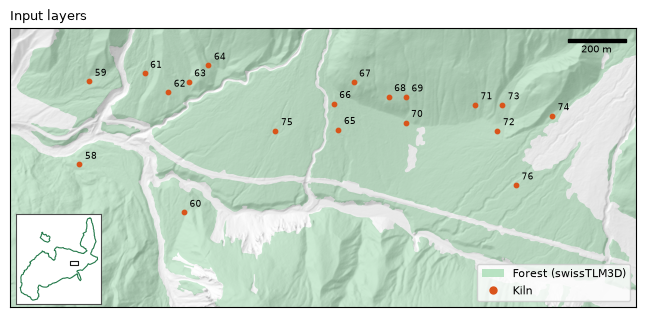

In [23]:
snp_line = gpd.GeoDataFrame(geometry=snp.boundary, crs=CRS)
OVERVIEW = tuple(kilns.total_bounds + np.array([-500, -500, 500, 500]))

fig, ax = map_figure(VIEW)
add_hillshade(ax, alpha=0.3)
draw(ax, [
    (forest, dict(color=C_FOREST, label="Forest (swissTLM3D)", alpha=0.8)),
    (kilns, dict(color=C_KILN, markersize=10, label="Kiln")),
], title="Input layers", bounds=VIEW)
label_points(ax, kilns, ID_COLUMN, VIEW)
add_inset(ax)
save_map(fig, "map1_input_layers")

## Step 2: Forest inside the park
The forest polygons are repaired (TLM layers often contain a few invalid polygons), fused into one shape and cut to the park boundary. This shape is what "in forest" means for both the kilns and the controls.

In [6]:
forest["geometry"] = forest.make_valid()
forest = forest.explode(index_parts=False)             # split mixed geometries into single parts
forest = forest[forest.geom_type == "Polygon"]         # keep only the polygons
park = union(snp)
forest_park = union(forest).intersection(park)
prepare(forest_park)                      # makes the many point tests below fast
forest_park_gdf = gpd.GeoDataFrame(geometry=[forest_park], crs=CRS)
print(f"Forest inside the park: {forest_park.area / 1e6:.1f} km² "
      f"({forest_park.area / park.area:.0%} of the park)")

Forest inside the park: 51.4 km² (30% of the park)


## Step 3: Candidate area
Forest inside the park, minus a 48 m buffer around every kiln. Any point in this area is far enough from all kilns that its rings can't overlap theirs.

Candidate area: 51.1 km²


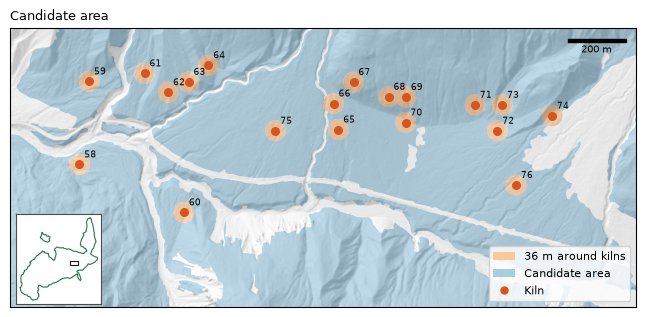

In [28]:
exclusion = union(kilns.buffer(MIN_DIST_KILN))
area = forest_park.difference(exclusion)
prepare(area)
area_gdf = gpd.GeoDataFrame(geometry=[area], crs=CRS)
exclusion_gdf = gpd.GeoDataFrame(geometry=[exclusion], crs=CRS)
print(f"Candidate area: {area.area / 1e6:.1f} km²")

fig, ax = map_figure(VIEW)
add_hillshade(ax, alpha=0.3)
draw(ax, [
    (exclusion_gdf, dict(color=C_BUFFER, alpha=0.8, label=f"{MIN_DIST_KILN} m around kilns")),
    (area_gdf, dict(color=C_AREA, label="Candidate area", alpha=1)),
    (kilns, dict(color=C_KILN, markersize=30, label="Kiln")),
], title="Candidate area", bounds=VIEW)
label_points(ax, kilns, ID_COLUMN, VIEW)
add_inset(ax)
save_map(fig, "map2_candidate_area")

## Step 4: Check the kilns
The same rules that apply to the controls are checked for the kilns: inside the park, enough forest along their rays, terrain values available, and (if the height raster is there) enough data. Kilns that fail get no controls, and should be **left out of the ring analysis as well**, so both sides follow the same rules. The table is saved as `kiln_checks_2056.csv`.

In [8]:
kx, ky = kilns.geometry.x.to_numpy(), kilns.geometry.y.to_numpy()
kilns["in_snp"] = kilns.within(park)
kilns["forest_share"] = [forest_share(x, y) for x, y in zip(kx, ky)]

with rasterio.open(DTM_FILE) as dtm:
    terr = [terrain(dtm, x, y) for x, y in zip(kx, ky)]
kilns[["elev", "slope", "aspect"]] = pd.DataFrame(terr, index=kilns.index,
                                                   columns=["elev", "slope", "aspect"])

if HEIGHT_RASTER:
    with rasterio.open(HEIGHT_RASTER) as hsrc:
        kilns["valid_share"] = [valid_share(hsrc, x, y) for x, y in zip(kx, ky)]
else:
    kilns["valid_share"] = 1.0

kilns["usable"] = (kilns["in_snp"]
                   & (kilns["forest_share"] >= MIN_FOREST)
                   & kilns["elev"].notna()
                   & (kilns["valid_share"] >= MIN_VALID))

print(f"{kilns['usable'].sum()} of {len(kilns)} kilns pass all checks")
cols = [ID_COLUMN, "in_snp", "forest_share", "valid_share", "elev", "slope", "aspect"]
failed = kilns.loc[~kilns["usable"], cols]
if len(failed):
    print("\nKilns that fail (no controls, leave out of the analysis too):")
    print(failed.round(2).to_string(index=False))

66 of 80 kilns pass all checks

Kilns that fail (no controls, leave out of the analysis too):
 ID_PAROLINI  in_snp  forest_share  valid_share    elev  slope  aspect
           2    True          0.02         1.00 1629.67   0.82   76.61
           3    True          0.00         0.97 1629.65   0.26  243.35
           4    True          0.00         0.99 1629.65   0.00  108.43
           5    True          0.00         1.00 1629.65   0.00  109.44
           7    True          0.81         1.00 1742.38  37.77  325.53
          11    True          0.00         1.00 2190.67  32.08   51.58
          12   False          0.00         0.00     NaN    NaN     NaN
          15    True          0.81         1.00 2115.18  18.21  201.43
          31    True          0.00         1.00 2220.02  28.88  350.41
          32    True          0.00         1.00 2197.44  31.33  330.35
          50    True          0.76         1.00 2029.97  14.70  222.30
          52    True          0.52         1.00 2018.9

14 kilns excluded:
 OBJECTID  ID_PAROLINI NAME ZEITRAUM REMARKS  in_snp  forest_share        elev     slope     aspect  valid_share  usable
        2            2 None     None    None    True      0.020833 1629.671554  0.823723  76.613427     1.000000   False
        3            3 None     None    None    True      0.000000 1629.653587  0.261395 243.349333     0.972222   False
        4            4 None     None    None    True      0.000000 1629.652600  0.000187 108.434949     0.986111   False
        5            5 None     None    None    True      0.000000 1629.652886  0.000266 109.440035     1.000000   False
        7            7 None     None    None    True      0.805556 1742.377388 37.768942 325.533264     1.000000   False
       11           11 None     None    None    True      0.000000 2190.674454 32.076607  51.581019     1.000000   False
       12           12 None     None    None   False      0.000000         NaN       NaN        NaN     0.000000   False
       15    

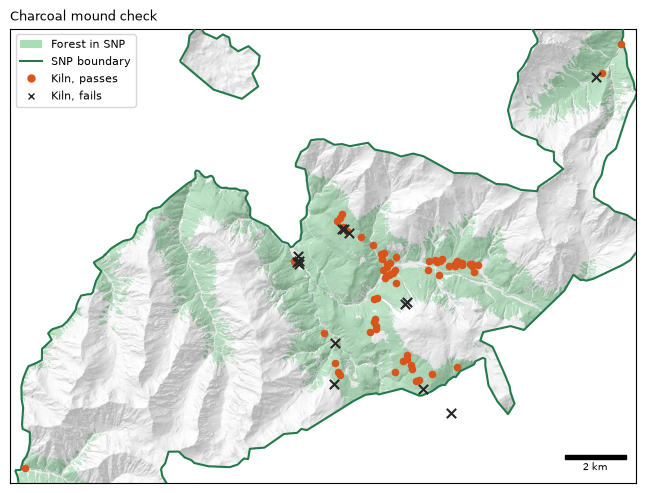

In [34]:
fig, ax = map_figure(OVERVIEW)
add_hillshade(ax, alpha=0.3, bounds=OVERVIEW, clip=snp)
draw(ax, [(forest_park_gdf, dict(color=C_FOREST, label="Forest in SNP")),
    (snp_line, dict(color=C_SNP, linewidth=1.5, label="SNP boundary")),
    (kilns[kilns["usable"]], dict(color=C_KILN, markersize=20, label="Kiln, passes")),
    (kilns[~kilns["usable"]], dict(color="0.15", marker="x", markersize=45, label="Kiln, fails")),
], title="Charcoal mound check", bounds=OVERVIEW, legend_loc="upper left", scalebar_loc="lower right")
save_map(fig, "map3_kiln_checks")
failed = kilns[~kilns["usable"]]
print(f"{len(failed)} kilns excluded:")
print(failed.drop(columns="geometry").to_string(index=False))

## Step 5: Place the controls
For each usable kiln, random candidates are drawn 50–100 m away (spread evenly over the area of that ring), and only those inside the candidate area are kept. They are then tried one by one, and a candidate is rejected if it is

- closer than 48 m to a control already placed,
- less than 90% forest along its rays,
- missing data in the height raster,
- too different in terrain from its kiln.

The first three that pass are kept. The counts at the end show which rule rejected how many candidates.

In [18]:
rng = np.random.default_rng(SEED)
placed = []
rejected = {"spacing": 0, "forest": 0, "coverage": 0, "terrain": 0}

dtm = rasterio.open(DTM_FILE)
hsrc = rasterio.open(HEIGHT_RASTER) if HEIGHT_RASTER else None

for _, k in kilns[kilns["usable"]].iterrows():
    x0, y0 = k.geometry.x, k.geometry.y
    bearing = rng.uniform(0, 2 * np.pi, N_CANDIDATES)
    d = np.sqrt(rng.uniform(SEARCH_MIN ** 2, SEARCH_MAX ** 2, N_CANDIDATES))
    cand_x, cand_y = x0 + d * np.sin(bearing), y0 + d * np.cos(bearing)
    keep = contains_xy(area, cand_x, cand_y)

    found = 0
    for x, y in zip(cand_x[keep], cand_y[keep]):
        if found == N_PER_KILN:
            break
        if placed:
            px = np.array([p["x"] for p in placed])
            py = np.array([p["y"] for p in placed])
            if np.hypot(px - x, py - y).min() < MIN_DIST_CTRL:
                rejected["spacing"] += 1
                continue
        fs = forest_share(x, y)
        if fs < MIN_FOREST:
            rejected["forest"] += 1
            continue
        vs = valid_share(hsrc, x, y) if hsrc else 1.0
        if vs < MIN_VALID:
            rejected["coverage"] += 1
            continue
        e, s, a = terrain(dtm, x, y)
        bad_terrain = (np.isnan(e)
                       or abs(e - k["elev"]) > MAX_ELEV_DIFF
                       or abs(s - k["slope"]) > MAX_SLOPE_DIFF
                       or (k["slope"] > FLAT_SLOPE and angle_diff(a, k["aspect"]) > MAX_ASPECT_DIFF))
        if bad_terrain:
            rejected["terrain"] += 1
            continue
        found += 1
        placed.append({ID_COLUMN: f"C{k[ID_COLUMN]}_{found}", "kiln_id": k[ID_COLUMN],
                       "x": x, "y": y, "dist_to_kiln": float(np.hypot(x - x0, y - y0)),
                       "forest_share": fs, "valid_share": vs,
                       "elev": e, "slope": s, "aspect": a})

dtm.close()
if hsrc:
    hsrc.close()

controls = gpd.GeoDataFrame(placed, geometry=gpd.points_from_xy(
    [p["x"] for p in placed], [p["y"] for p in placed]), crs=CRS)

n_per = controls.groupby("kiln_id").size().reindex(kilns.loc[kilns["usable"], ID_COLUMN],
                                                   fill_value=0)
print(f"{len(controls)} controls for {kilns['usable'].sum()} usable kilns")
print("Candidates rejected by:", rejected)
short = n_per[n_per < N_PER_KILN]
if len(short):
    print(f"\nKilns with fewer than {N_PER_KILN} controls:")
    print(short.to_string())

189 controls for 66 usable kilns
Candidates rejected by: {'spacing': 4199, 'forest': 1862, 'coverage': 0, 'terrain': 6851}

Kilns with fewer than 3 controls:
ID_PAROLINI
10    1
35    2
36    2
37    1
64    2
80    1


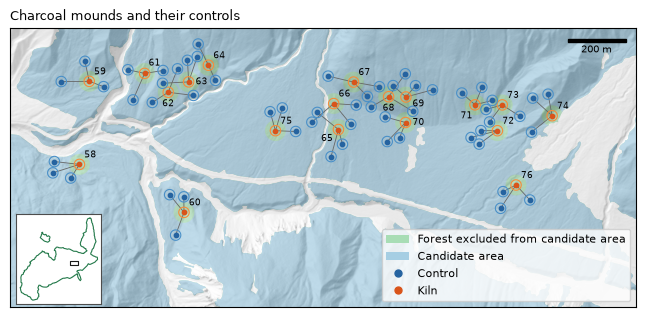

In [35]:
# Lines from every control to its kiln
kiln_xy = kilns.set_index(ID_COLUMN).geometry
links = gpd.GeoDataFrame(
    geometry=[LineString([p, kiln_xy[kid]]) for p, kid in zip(controls.geometry, controls["kiln_id"])],
    crs=CRS)

LABEL_ANGLES = {61: 35, 62: 180, 63: 90, 70: 90, 71: 200, 65: 230, 69: 110, 68: 180}

fig, ax = map_figure(VIEW)
add_hillshade(ax, alpha=0.3)
draw(ax, [
    (forest_park_gdf, dict(color=C_FOREST, label="Forest excluded from candidate area")),
    (area_gdf, dict(color=C_AREA, label="Candidate area")),
    (links, dict(color="0.4", linewidth=0.6)),
    (gpd.GeoDataFrame(geometry=kilns.buffer(RADIUS), crs=CRS),
     dict(facecolor="none", edgecolor=C_KILN_RING, linewidth=0.8)),
    (gpd.GeoDataFrame(geometry=controls.buffer(RADIUS), crs=CRS),
     dict(facecolor="none", edgecolor=C_CTRL_RING, linewidth=0.8)),
    (controls, dict(color=C_CTRL, markersize=10, label="Control")),
    (kilns, dict(color=C_KILN, markersize=10, label="Kiln")),
], title="Charcoal mounds and their controls", bounds=VIEW)
label_points(ax, kilns, ID_COLUMN, VIEW, LABEL_ANGLES)
add_inset(ax)
save_map(fig, "map4_Kilns_and_their_controls")

In Map 5 the circles show the 24 m rings: red around kilns, blue around controls. They should never overlap.

## Step 6: Check the terrain match
The differences between each control and its kiln. Small differences make the comparison fair; this table can go into the paper to show the controls are comparable.

Terrain of usable kilns vs. controls:
       kilns       controls      
        elev slope     elev slope
mean  1936.0  18.9   1942.8  19.5
std    133.3   7.7    130.4   7.7
min   1644.3   6.2   1652.9   4.8
max   2205.7  35.5   2228.7  39.7

Differences control - kiln:
       dist_to_kiln  elev_diff  slope_diff  aspect_diff
count         189.0      189.0       189.0        189.0
mean           76.7        2.4         0.7         17.8
std            15.2       15.0         4.7         12.7
min            50.0      -28.5        -9.8          0.1
25%            62.2       -8.3        -2.1          6.7
50%            77.6        1.8         0.5         15.9
75%            90.6       15.9         3.7         27.0
max           100.0       29.9         9.8         44.2


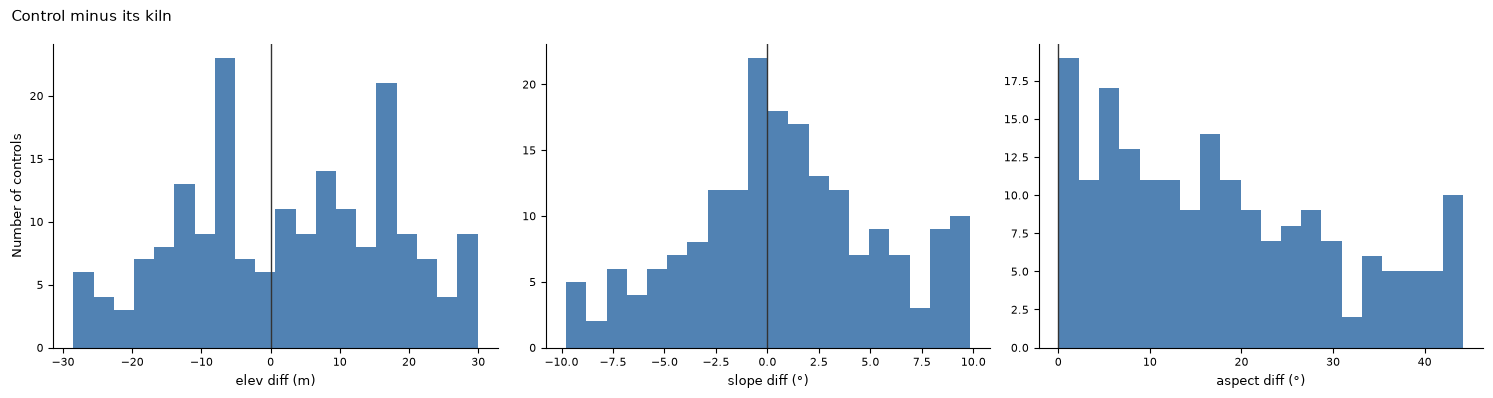

In [242]:
kiln_terr = kilns.set_index(ID_COLUMN)[["elev", "slope", "aspect"]]
cmp = controls[[ID_COLUMN, "kiln_id", "dist_to_kiln", "elev", "slope", "aspect"]].join(
    kiln_terr, on="kiln_id", rsuffix="_kiln")
cmp["elev_diff"] = cmp["elev"] - cmp["elev_kiln"]
cmp["slope_diff"] = cmp["slope"] - cmp["slope_kiln"]
cmp["aspect_diff"] = angle_diff(cmp["aspect"], cmp["aspect_kiln"])

print("Terrain of usable kilns vs. controls:")
print(pd.concat({"kilns": kilns.loc[kilns["usable"], ["elev", "slope"]].describe().loc[["mean", "std", "min", "max"]],
                 "controls": controls[["elev", "slope"]].describe().loc[["mean", "std", "min", "max"]]},
                axis=1).round(1).to_string())
print("\nDifferences control - kiln:")
print(cmp[["dist_to_kiln", "elev_diff", "slope_diff", "aspect_diff"]].describe().round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, unit in zip(axes, ["elev_diff", "slope_diff", "aspect_diff"], ["m", "°", "°"]):
    ax.hist(cmp[col].dropna(), bins=20, color=C_CTRL, alpha=0.8)
    ax.axvline(0, color="0.2", linewidth=1)
    ax.set_xlabel(f"{col.replace('_', ' ')} ({unit})")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of controls")
fig.suptitle("Control minus its kiln", x=0.01, ha="left")
plt.tight_layout()
save_map(fig, "graph1_control_minus_its_kiln")

## Step 7: Save

In [243]:
controls.drop(columns=["x", "y"]).to_file(OUT_POINTS, layer="controls")
area_gdf.to_file(OUT_AREA, layer="area")
kilns.drop(columns="geometry").assign(x=kx, y=ky).to_csv(OUT_KILN_CHECK, index=False)
print(f"Saved {OUT_POINTS}, {OUT_AREA}, {OUT_KILN_CHECK}")

excluded = kilns.loc[~kilns["usable"], ID_COLUMN].tolist()
print(f"Kilns to leave out of the ring analysis: {excluded}")

Saved controls_2056.gpkg, control_area_2056.gpkg, kiln_checks_2056.csv
Kilns to leave out of the ring analysis: [2, 3, 4, 5, 7, 11, 12, 15, 31, 32, 50, 52, 53, 78]


## Next step

Run the ring analysis on the controls with exactly the same settings as for the kilns:

```python
from kiln_ring_analysis_function import kiln_ring_analysis
out_ctrl = kiln_ring_analysis({"gpkg": "controls_2056.gpkg", "comment": "controls"})
```

Leave the kilns listed in Step 7 out of the kiln results as well. The column `kiln_id` links every control to its kiln for paired comparisons.